# Example of the aitlas toolbox in the context of semantic segmentation

## Import the required packages

In [ ]:
import sys
sys.path.insert(0, "..")  # makes the datasets package of this repository importable
from datasets import HephaestusSemanticSegmentationDataset
from aitlas.utils import image_loader
from aitlas.models import DeepLabV3
from aitlas.transforms import MinMaxNormTranspose

## Visualize images and masks

Total number of patches: 2247


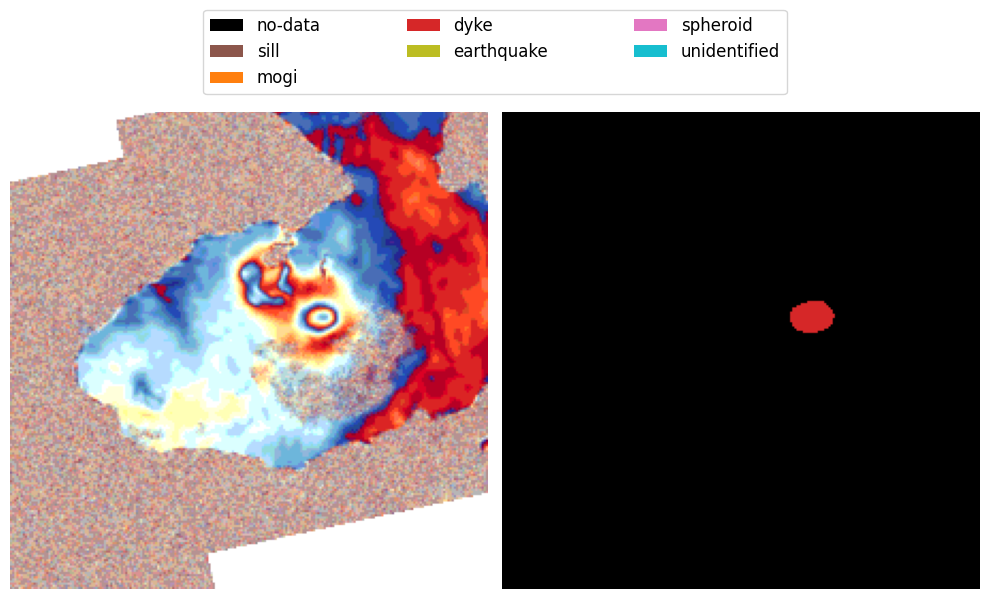

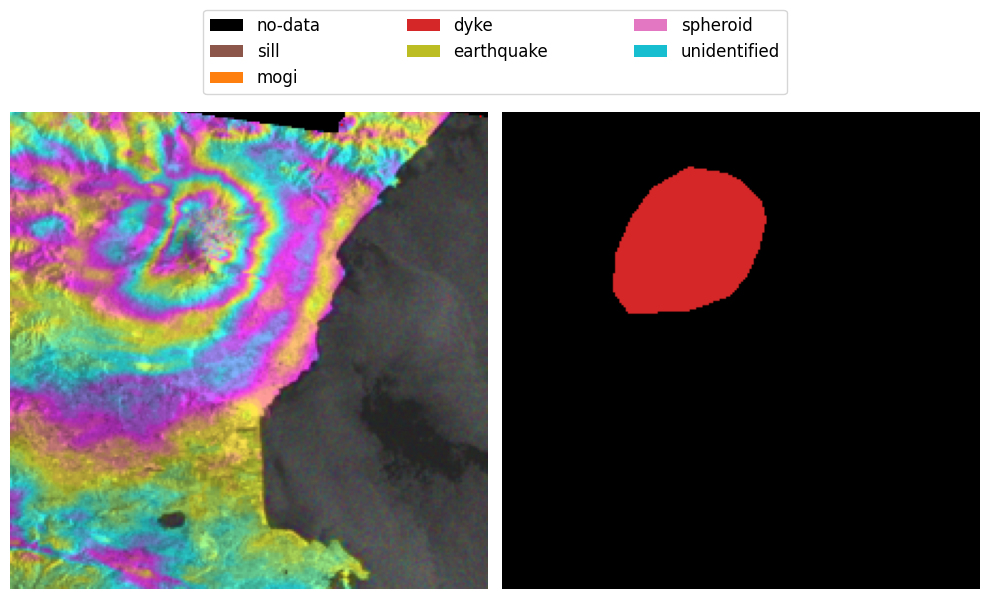

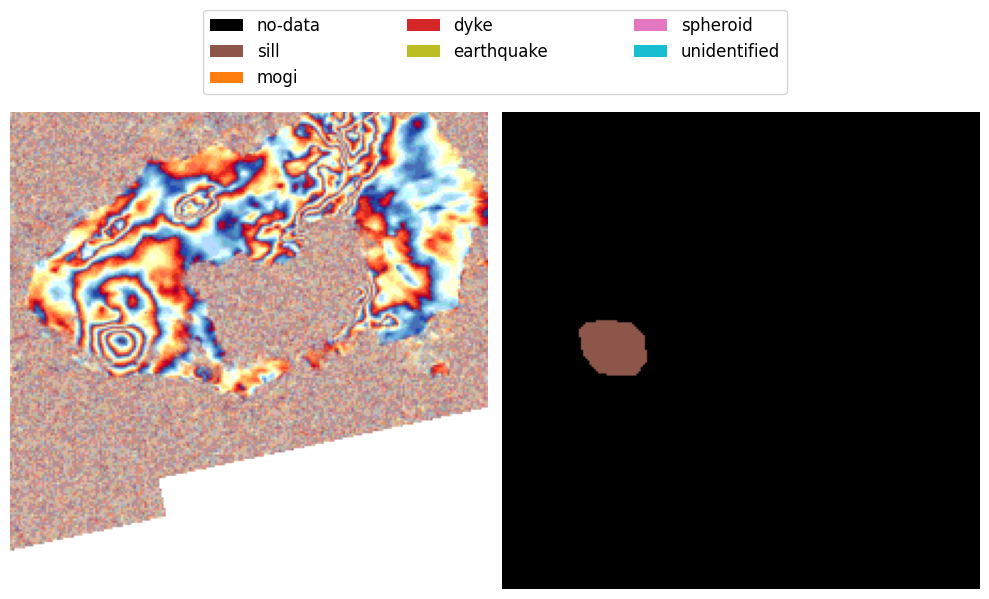

In [ ]:
dataset_config = {
    "data_dir": "./data/Hephaestus_sem_seg"
}
dataset = HephaestusSemanticSegmentationDataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")
dataset.show_image(1);
dataset.show_image(350);
dataset.show_image(1500);

In [7]:
dataset.data_distribution_table()

,Number of pixels
no-data,109483120.0
sill,495327.0
mogi,1817981.0
dyke,774557.0
earthquake,8869.0
spheroid,81156.0
unidentified,84459.0


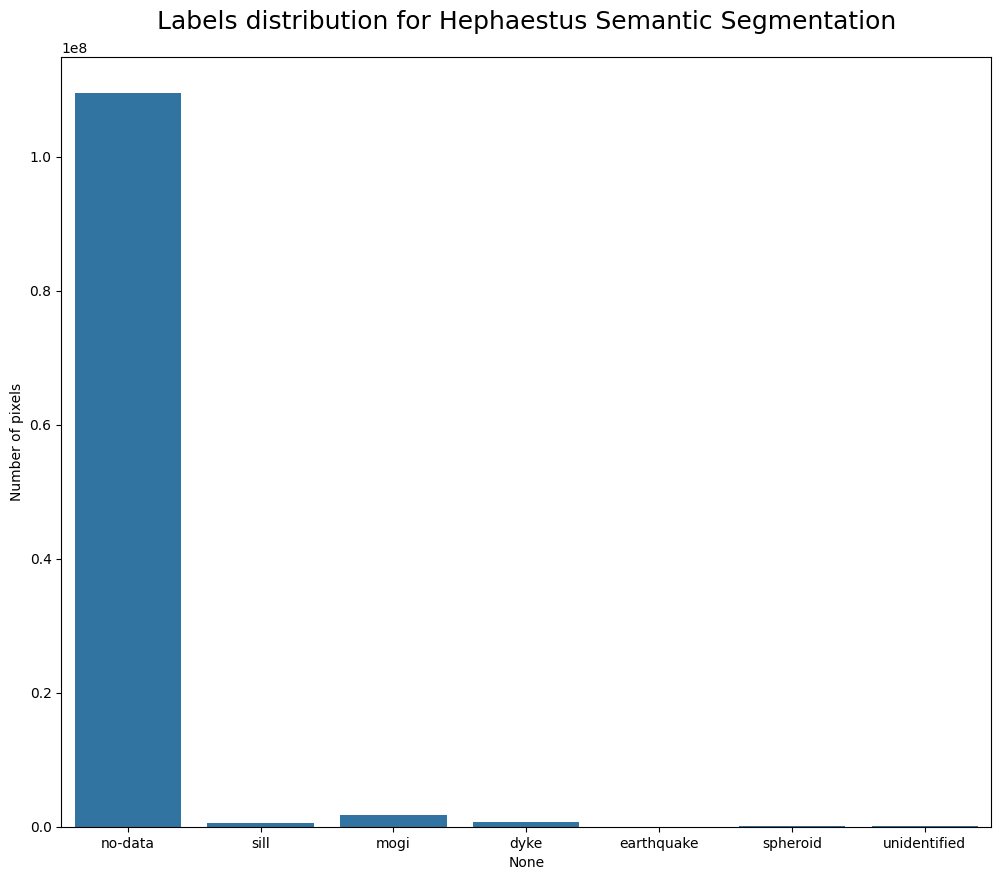

In [8]:
dataset.data_distribution_barchart();

## Load training data

In [ ]:
train_dataset_config = {
    "batch_size": 7,
    "shuffle": True,
    "num_workers": 4,
    "data_dir": "./data/Hephaestus_sem_seg",
    "csv_file": "./data/Hephaestus_sem_seg/train.csv",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"], 
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"] 
}
train_dataset = HephaestusSemanticSegmentationDataset(train_dataset_config)
len(train_dataset)

1799

## Create the model

In [ ]:
epochs = 10
model_directory = "./data/Hephaestus_sem_seg"
model_config = {
    "num_classes": 7, 
    "learning_rate": 0.0001,
    "pretrained": True, 
    "threshold": 0.5,
    "metrics": ["iou"]
}

model = DeepLabV3(model_config)
model.prepare()

## Start the training

In [12]:
model.train_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    run_id='1'
);

2025-03-19 09:07:45,563 INFO Starting training.
training: 100%|██████████| 257/257 [00:21<00:00, 11.81it/s]
2025-03-19 09:08:07,408 INFO epoch: 1, time: 22, loss:  0.54674
testing on train set: 100%|██████████| 257/257 [00:08<00:00, 30.07it/s]
2025-03-19 09:08:17,501 INFO IOU:0.955672871748111, IOU mean:0.24951910764218024, IOU per Class:[0.98093852 0.         0.41538404 0.35031119 0.         0.
 0.        ]
training: 100%|██████████| 257/257 [00:21<00:00, 11.75it/s]
2025-03-19 09:08:39,388 INFO epoch: 2, time: 22, loss:  0.16015
testing on train set: 100%|██████████| 257/257 [00:08<00:00, 30.29it/s]
2025-03-19 09:08:47,892 INFO IOU:0.9546801860618537, IOU mean:0.1824686349555564, IOU per Class:[0.9770091  0.         0.30027135 0.         0.         0.
 0.        ]
training: 100%|██████████| 257/257 [00:20<00:00, 12.27it/s]
2025-03-19 09:09:08,848 INFO epoch: 3, time: 21, loss:  0.06302
testing on train set: 100%|██████████| 257/257 [00:08<00:00, 29.81it/s]
2025-03-19 09:09:17,490 INFO

## Evaluate the model

In [ ]:
test_dataset_config = {
    "batch_size": 4,
    "shuffle": False,
    "num_workers": 4,
    "data_dir": "./data/Hephaestus_sem_seg",
    "csv_file": "./data/Hephaestus_sem_seg/val.csv",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"], 
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"] 
}

test_dataset = HephaestusSemanticSegmentationDataset(test_dataset_config)
print(len(test_dataset))

model = DeepLabV3(model_config)
model.prepare()
model.running_metrics.reset()
model_path = "./data/Hephaestus_sem_seg/checkpoint.pth.tar"
model.evaluate(dataset=test_dataset, model_path=model_path)
model.running_metrics.get_scores(model.metrics)

224


2025-03-19 09:17:37,744 INFO Loading checkpoint /home/dragik/data/FAIR_EO/Hephaestus_sem_seg/checkpoint.pth.tar
2025-03-19 09:17:38,126 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/Hephaestus_sem_seg/checkpoint.pth.tar at epoch 11
testing on test set: 100%|██████████| 56/56 [00:01<00:00, 37.99it/s]


[{'IOU': 0.9709820866195582,
  'IOU mean': 0.24241441029432464,
  'IOU per Class': array([0.98758314, 0.        , 0.70931774, 0.        , 0.        ,
         0.        , 0.        ])}]

## Predictions

2025-03-19 09:17:46,411 INFO Loading checkpoint /home/dragik/data/FAIR_EO/Hephaestus_sem_seg/checkpoint.pth.tar
2025-03-19 09:17:47,116 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/Hephaestus_sem_seg/checkpoint.pth.tar at epoch 11


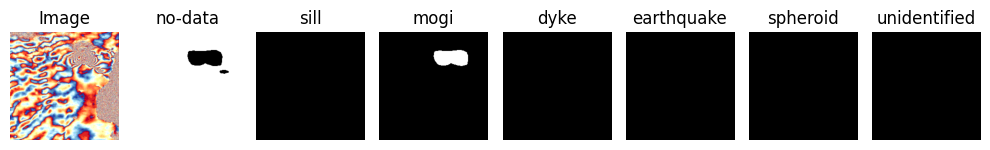

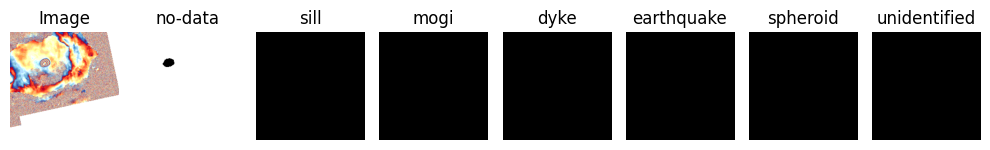

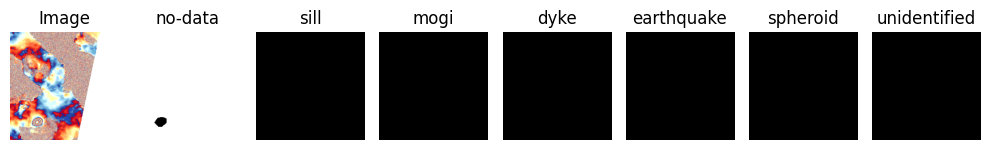

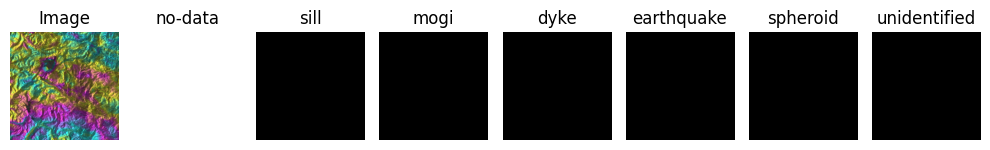

In [ ]:
model_path = "./data/Hephaestus_sem_seg/checkpoint.pth.tar"
labels = ["no-data","sill","mogi","dyke","earthquake","spheroid","unidentified"]
transform = MinMaxNormTranspose()
model.load_model(model_path)
csv_file = "./data/Hephaestus_sem_seg/test.csv"

test_list = []
with open(csv_file, mode ='r')as file:
    csvFile = csv.reader(file)
    for lines in csvFile:
        test_list.append(lines[0])

image = image_loader('./data/Hephaestus_sem_seg/' + test_list[0])
fig = model.predict_masks(image, labels, transform)

image = image_loader('./data/Hephaestus_sem_seg/' + test_list[1])
fig = model.predict_masks(image, labels, transform)

image = image_loader('./data/Hephaestus_sem_seg/' + test_list[10])
fig = model.predict_masks(image, labels, transform)

image = image_loader('./data/Hephaestus_sem_seg/' + test_list[50])
fig = model.predict_masks(image, labels, transform)